<a href="https://colab.research.google.com/github/bforoura/DBMS/blob/master/Module6_ChromaDB/class_exercise_chromadb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Semantic Search and Metadata Filtering with ChromaDB**

* Let's perform the following tasks:
   1) build a vector database collection using ChromaDB
   2) ingest structured course descriptions with metadata
   3) execute semantic similarity queries
   4) combine vector search with relational metadata filters.


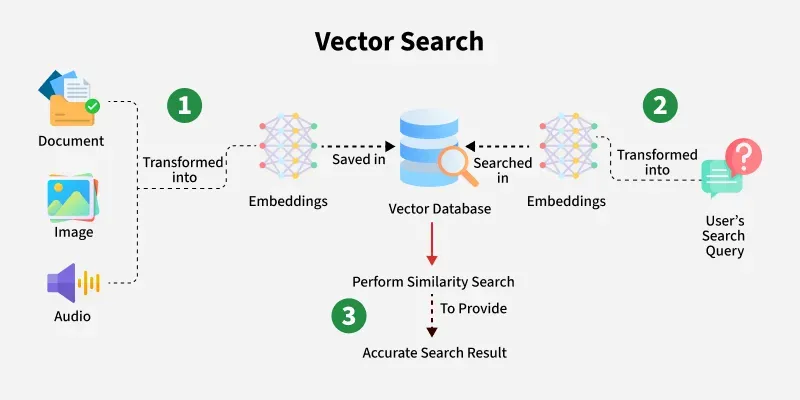

# **Task 1: Environment Setup**

Install the required ChromaDB library in your Google Colab environment.

In [1]:
!pip install chromadb

# **Task 2: Import Libraries and Initialize**

Import ChromaDB and initialize a client for **in-memory vector storage**.

In [2]:
import chromadb

# Initialize the Chroma client
client = chromadb.Client()

print("ChromaDB initialized successfully.")
print(f"Chroma version: {chromadb.__version__}")

ChromaDB initialized successfully.
Chroma version: 1.5.9


# **Task 3: Create a Collection and Ingest Data**

Let's Create a collection named **cs_course_catalog** and populate it with documents representing computer science courses, complete with metadata including course codes, categories, and credit hours.

In [3]:
# Create or get the collection
collection = client.get_or_create_collection(
    name="cs_course_catalog",
    metadata={"description": "Departmental course catalog for semantic retrieval"}
)

# Add documents, unique IDs, and metadata
collection.add(
    ids=["course_120", "course_351", "course_331", "course_362", "course_368"],
    documents=[
        "Introduction to programming in Java covering object-oriented design, classes, inheritance, polymorphism, and basic data structures.",
        "Database Management Systems explores relational algebra, SQL querying, transaction management, B-Trees, and NoSQL document stores.",
        "Operating Systems covers process scheduling, virtual memory management, synchronization primitives, and POSIX multithreading.",
        "Machine Learning focuses on supervised classification pipelines, decision trees, support vector machines, and model evaluation metrics.",
        "Deep Learning and Generative AI examines neural network architectures, transformer models, self-attention mechanisms, and prompt tuning."
    ],
    metadatas=[
        {"course_code": "CSC 120", "category": "Programming", "credits": 4},
        {"course_code": "CSC 351", "category": "Data", "credits": 3},
        {"course_code": "CSC 331", "category": "Systems", "credits": 4},
        {"course_code": "CSC 362", "category": "AI", "credits": 3},
        {"course_code": "CSC 368", "category": "GenAI", "credits": 3}
    ]
)

print(f"Successfully added {collection.count()} courses to the vector collection.")

/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:03<00:00, 26.5MiB/s]


Successfully added 5 courses to the vector collection.


# **Task 4: Execute Basic Semantic Queries**

Query the vector database using **natural language phrasing** that **does not contain exact keyword matches** from the documents.

In [4]:
# Define a natural language query
query_string = "Where can I learn about relational databases and SQL queries?"

# Execute the query
results = collection.query(
    query_texts=[query_string],
    n_results=3,
    include=["documents", "metadatas", "distances"]
)

print(f"Query: {query_string}\n" + "-" * 60)
for idx, (doc_id, doc, meta, dist) in enumerate(zip(results["ids"][0], results["documents"][0], results["metadatas"][0], results["distances"][0])):
    print(f"Rank {idx + 1}:")
    print(f"  ID: {doc_id} | Code: {meta['course_code']} | Category: {meta['category']}")
    print(f"  Document: {doc}")
    print(f"  Distance Score: {dist:.4f}")
    print()

Query: Where can I learn about relational databases and SQL queries?
------------------------------------------------------------
Rank 1:
  ID: course_351 | Code: CSC 351 | Category: Data
  Document: Database Management Systems explores relational algebra, SQL querying, transaction management, B-Trees, and NoSQL document stores.
  Distance Score: 0.7638

Rank 2:
  ID: course_120 | Code: CSC 120 | Category: Programming
  Document: Introduction to programming in Java covering object-oriented design, classes, inheritance, polymorphism, and basic data structures.
  Distance Score: 1.5263

Rank 3:
  ID: course_362 | Code: CSC 362 | Category: AI
  Document: Machine Learning focuses on supervised classification pipelines, decision trees, support vector machines, and model evaluation metrics.
  Distance Score: 1.7021



# **Task 5: Advanced Feature - Combining Vector Search with Metadata Filtering**

Let's do a hybrid retrieval by restricting semantic search results to a specific metadata category (category: AI).


In [5]:
# Query focused on neural concepts, but filtered strictly to AI category
query_string = "Advanced models and architectures"

filtered_results = collection.query(
    query_texts=[query_string],
    n_results=2,
    where={"category": "AI"},
    include=["documents", "metadatas", "distances"]
)

print(f"Query: {query_string} (Filtered by category == 'AI')\n" + "-" * 60)
for idx, (doc_id, doc, meta, dist) in enumerate(zip(filtered_results["ids"][0], filtered_results["documents"][0], filtered_results["metadatas"][0], filtered_results["distances"][0])):
    print(f"Rank {idx + 1}:")
    print(f"  ID: {doc_id} | Code: {meta['course_code']} | Credits: {meta['credits']}")
    print(f"  Document: {doc}")
    print(f"  Distance Score: {dist:.4f}")
    print()

Query: Advanced models and architectures (Filtered by category == 'AI')
------------------------------------------------------------
Rank 1:
  ID: course_362 | Code: CSC 362 | Credits: 3
  Document: Machine Learning focuses on supervised classification pipelines, decision trees, support vector machines, and model evaluation metrics.
  Distance Score: 1.4585



# **Question 1: Distance Analysis**

Modify the query to search for "**threads and CPU scheduling**" and examine the resulting distance scores

In [6]:
query_string = "threads and CPU scheduling"

results = collection.query(
    query_texts=[query_string],
    n_results=1,
    include=["documents", "metadatas", "distances"]
)

print(f"Query: {query_string}")
print(f"Rank 1 ID: {results['ids'][0][0]} | Code: {results['metadatas'][0][0]['course_code']}")
print(f"Distance Score: {results['distances'][0][0]:.4f}")

Query: threads and CPU scheduling
Rank 1 ID: course_331 | Code: CSC 331
Distance Score: 1.1035


# **Explanation**

1) Even though the exact phrase "**threads and CPU schedulin**g" does not appear verbatim, the embedding model maps the query close to the text "**process scheduling... synchronization primitives, and POSIX multithreading**."

2) The **distance score** will be relatively low (typically under 1.0 depending on the exact model run), reflecting **close geometric proximity in the 384-dimensional vector space**.

# **Question 2: Metadata Filtering**


Search for "**object-oriented design**" while restricting results exclusively to courses where **credits == 4**.

In [7]:
query_string = "object-oriented design"

filtered_results = collection.query(
    query_texts=[query_string],
    n_results=1,
    where={"credits": 4},
    include=["documents", "metadatas", "distances"]
)

print(f"Query: {query_string} (Filtered by credits == 4)")
print(f"Rank 1 ID: {filtered_results['ids'][0][0]} | Code: {filtered_results['metadatas'][0][0]['course_code']}")
print(f"Document: {filtered_results['documents'][0][0]}")

Query: object-oriented design (Filtered by credits == 4)
Rank 1 ID: course_120 | Code: CSC 120
Document: Introduction to programming in Java covering object-oriented design, classes, inheritance, polymorphism, and basic data structures.


# **Explanation**

1) Both course_120 (CSC 120, 4 credits) and course_331 (CSC 331, 4 credits) match the metadata filter credits == 4.

2) However, because the semantic query explicitly targets "object-oriented design", course_120 is surfaced as the top result because its **conceptual meaning aligns directly with the query text**.

# **Question 3: Embedding Model Behavior**

Add a **physics** or **chemistry** course to the collection and observe how querying for a computer science topic affects the distance score of the new document.

In [8]:
# Add a non-CS course to the existing collection
collection.add(
    ids=["course_999"],
    documents=[
        "Quantum Mechanics covers wave functions, Schrödinger equations, tunneling, and subatomic particle-wave duality."
    ],
    metadatas=[
        {"course_code": "PHY 301", "category": "Physics", "credits": 4}
    ]
)

# Run a computer science query
query_string = "Relational algebra and SQL indexing"

results = collection.query(
    query_texts=[query_string],
    n_results=5,  # Retrieve all documents to check positioning
    include=["documents", "metadatas", "distances"]
)

print(f"Query: {query_string}\n" + "-" * 50)
for idx, (doc_id, meta, dist) in enumerate(zip(results["ids"][0], results["metadatas"][0], results["distances"][0])):
    print(f"Rank {idx + 1}: ID: {doc_id} ({meta.get('course_code', 'N/A')}) | Distance: {dist:.4f}")

Query: Relational algebra and SQL indexing
--------------------------------------------------
Rank 1: ID: course_351 (CSC 351) | Distance: 0.9876
Rank 2: ID: course_120 (CSC 120) | Distance: 1.6182
Rank 3: ID: course_331 (CSC 331) | Distance: 1.8423
Rank 4: ID: course_999 (PHY 301) | Distance: 1.9729
Rank 5: ID: course_368 (CSC 368) | Distance: 2.0266


# **Explanation**

1) **Rank 4 (PHY 301, Distance: 1.97):**
   * The physics course appears near the bottom of the retrieval set with a high distance score.
   * This demonstrates how high-dimensional embedding spaces separate entirely different academic disciplines into distinct geometric clusters.

2) **Rank 5 (CSC 368, Distance: 2.02)**:
  * This computer science course has the highest distance score of the set.
  * Depending on its specific curriculum focus such as hardware design or computer graphics, its vector representation lies far away from database topics in the vector coordinate space, making it even **more geometrically distant from the query** than the physics course.